# Trial seven: the minimum model and the sensitive parameters

Which rules are essential for a school? Which parameters change the behaviour a lot, and which hardly matter? What is the simplest model that still works? The story is in [chapter 7 of the README](../README.md#chapter-7-trial-seven-the-minimum-model-and-the-sensitive-parameters).

- **Part A:** switch rules off.
- **Part B:** one parameter at a time, from the Puckett base with a random start; **B2 (extra):** the same with the group already together.
- **Part C:** the minimal model, tested on 10 new seeds.
- **Part D (extra):** one crowding rule that explains r_r, r_o and N at once.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (it contains study_code/) and let Python import the shared study code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
sys.path.insert(0, str(CHECKS_FOLDER / "study_code"))

import study_tools
from study_tools import (
    A0_SETTINGS, PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR, EXTRA_COLOR,
    change_settings, final_label_counts, load_results, run_many, short_table, summarize, translate,
)

# Where this trial keeps its saved results and its README figure.
DATA_FOLDER = CHECKS_FOLDER / "trial_seven_minimum_parameters" / "data"
FIGURE_FOLDER = CHECKS_FOLDER / "trial_seven_minimum_parameters" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## Settings

The names of rule sets, parameters and configurations are saved in the CSV files in Spanish (the saved results use them as keys); tables and figures show the English names defined here.

Switching a rule off does **not** move the zones: without orientation, the zone from 0.5 to 3 BL becomes silent. The extra "no gap" rows set r_o = 0.51 BL, so attraction starts right after repulsion.

In [2]:
SEEDS = list(range(10))
NEW_SEEDS = list(range(10, 20))   # part C is tested on seeds that no other part used

# Part A: (saved name, rules, English name).
RULE_SETS = [
    ("las tres", "repulsion+orientation+attraction", "all three"),
    ("repulsión + atracción", "repulsion+attraction", "repulsion + attraction"),
    ("repulsión + orientación", "repulsion+orientation", "repulsion + orientation"),
    ("orientación + atracción", "orientation+attraction", "orientation + attraction"),
    ("solo atracción", "attraction", "attraction only"),
    ("ninguna", "none", "none"),
]
NO_GAP_RULE_SETS = [
    ("repulsión + atracción, sin hueco", "repulsion+attraction", "repulsion + attraction, no gap"),
    ("solo atracción, sin hueco", "attraction", "attraction only, no gap"),
]
NO_GAP_ORIENTATION_RADIUS = 0.51

# Part B: (saved name, model option, values). The base value of each is run once, in the base row.
SENSITIVITY = [
    ("r_r (BL)", "repulsion_radius", [0.25, 0.5, 0.75, 1.0]),
    ("r_o (BL)", "orientation_radius", [0.55, 1.0, 2.0, 3.0, 4.0, 5.0]),
    ("r_a (BL)", "attraction_radius", [3.5, 4.5, 5.5, 7.0, 9.0]),
    ("campo visual (°)", "fov_degrees", [180.0, 230.0, 270.0, 320.0, 360.0]),
    ("giro máx. (rad/decisión)", "turn_per_decision", [0.25, 0.5, 1.0, 1.75, None]),
    ("ruido (rad/decisión)", "noise_per_decision", [0.0, 0.01, 0.05, 0.1, 0.2]),
    ("N (peces)", "n_fish", [10, 20, 40, 80]),
]
STEP_LENGTH_NAME = "ℓ (BL/decisión)"   # taken from trial six in part B, run again in part B2
ARENA_NAME = "arena (BL)"              # taken from trial five in part B, run again in part B2
LIGHT_RANGE = (0.025, 0.625)           # step lengths that light will cause (0.2 to 5 BL/s)

# Part B2: the same base with the group already together, plus step length and arena size.
COMPACT_SPREAD = 0.25
LIGHT_STEP_LENGTHS = [0.025, 0.05, 0.1, 0.2, 0.25, 0.375, 0.5, 0.625]
ARENA_SIZES = [20.0, 40.0]

# Sensitivity classes of the plan, fixed before running.
VERY_UNIT, VERY_DISTANCE = 0.2, 0.4        # very sensitive: a 0-1 metric changes > 0.2 or a distance > 40 %
SOME_UNIT, SOME_DISTANCE = 0.05, 0.1       # somewhat sensitive: changes of at least 0.05 or 10 %
UNIT_METRICS = ["polarization", "rotation", "largest_group_fraction", "collision_fraction"]
DISTANCE_METRICS = ["nnd", "centroid_distance"]

# Part C: the minimal model = A0 with the Puckett arena and a compact start.
LONGER_SWIM_DISTANCE = 3 * study_tools.SWIM_DISTANCE
MINIMAL_CHANGES = {"arena": 28.0, "initial_spread": COMPACT_SPREAD}
# (saved name, English name, start from "A4" or "minimal", changes)
PART_C = [
    ("Puckett completo (A4), inicio compacto", "full Puckett (A4), compact start", "A4",
     {"initial_spread": COMPACT_SPREAD}),
    ("mínimo (3 reglas, 360°, giro de golpe, sin ruido)", "minimal (3 rules, 360°, instant turns, no noise)",
     "minimal", {}),
    ("mínimo, inicio al azar", "minimal, random start", "minimal", {"initial_spread": 1.0}),
    ("mínimo sin atracción", "minimal without attraction", "minimal", {"rules": "repulsion+orientation"}),
    ("Puckett sin atracción, inicio compacto, 540 BL", "Puckett without attraction, compact start, 540 BL", "A4",
     {"initial_spread": COMPACT_SPREAD, "rules": "repulsion+orientation", "swim_distance": LONGER_SWIM_DISTANCE}),
    ("Puckett completo, inicio compacto, 540 BL", "full Puckett, compact start, 540 BL", "A4",
     {"initial_spread": COMPACT_SPREAD, "swim_distance": LONGER_SWIM_DISTANCE}),
]

# Part D: fish per area in a honeycomb packing with spacing r_r.
HONEYCOMB = np.pi / (2 * np.sqrt(3))   # about 0.9

# English names for saved values.
PARAMETER_NAMES = {
    "campo visual (°)": "field of view (°)", "giro máx. (rad/decisión)": "turn limit (rad/decision)",
    "ruido (rad/decisión)": "noise (rad/decision)", "N (peces)": "N (fish)",
    "ℓ (BL/decisión)": "step length (BL/decision)",
}
VALUE_NAMES = {"sin límite": "no limit"}

The configurations, built from the settings above.

In [3]:
def value_text(value):
    """How a value is written in the saved labels; None (no turn limit) is saved as "sin límite"."""
    if value is None:
        return "sin límite"
    return f"{value:g}"


def one_change(base_settings, name, key, value, value_label):
    """A base configuration with one parameter changed, labelled with that parameter and value."""
    settings = change_settings(base_settings, f"{name} = {value_label}", {key: value})
    settings["parameter"] = name
    settings["value"] = value_label
    return settings


def base_row(settings, label):
    """The base run of a sensitivity part."""
    base = change_settings(settings, label, {})
    base["parameter"] = "base"
    base["value"] = "base"
    return base


# Part A: every rule set for A0 and A4, plus the extra rows without the silent gap.
RULE_NAMES = {}
rule_runs = []
no_gap_runs = []
for base in [A0_SETTINGS, PUCKETT_SETTINGS]:
    for name, rules, english in RULE_SETS:
        settings = change_settings(base, f"{base['base']}: {name}", {"rules": rules})
        settings["rule_set"] = name
        rule_runs.append(settings)
        RULE_NAMES[name] = english
    for name, rules, english in NO_GAP_RULE_SETS:
        changes = {"rules": rules, "orientation_radius": NO_GAP_ORIENTATION_RADIUS}
        settings = change_settings(base, f"{base['base']}: {name}", changes)
        settings["rule_set"] = name
        no_gap_runs.append(settings)
        RULE_NAMES[name] = english

# Part B: the Puckett base with a random start, one parameter at a time.
sensitivity_runs = [base_row(PUCKETT_SETTINGS, "base (A4)")]
for name, key, values in SENSITIVITY:
    for value in values:
        if value != PUCKETT_SETTINGS[key]:
            sensitivity_runs.append(one_change(PUCKETT_SETTINGS, name, key, value, value_text(value)))

# Part B2: the same with a compact start, plus step length and arena size.
compact_base = change_settings(PUCKETT_SETTINGS, "base compacta (A4)", {"initial_spread": COMPACT_SPREAD})
compact_runs = [base_row(compact_base, "base compacta (A4)")]
for name, key, values in SENSITIVITY:
    for value in values:
        if value != PUCKETT_SETTINGS[key]:
            compact_runs.append(one_change(compact_base, name, key, value, value_text(value)))
for step_length in LIGHT_STEP_LENGTHS:
    speed = step_length / PUCKETT_SETTINGS["dt"]
    compact_runs.append(one_change(compact_base, STEP_LENGTH_NAME, "speed", speed, value_text(step_length)))
for arena in ARENA_SIZES:
    compact_runs.append(one_change(compact_base, ARENA_NAME, "arena", arena, value_text(arena)))

# Part C: the minimal model, the full Puckett model and two tests of attraction.
minimal_base = change_settings(A0_SETTINGS, "minimal", MINIMAL_CHANGES)
MINIMAL_NAMES = {}
minimal_runs = []
for saved_name, english_name, start, changes in PART_C:
    if start == "A4":
        minimal_runs.append(change_settings(PUCKETT_SETTINGS, saved_name, changes))
    else:
        minimal_runs.append(change_settings(minimal_base, saved_name, changes))
    MINIMAL_NAMES[saved_name] = english_name

## Run or load

In [4]:
rule_results = run_many(rule_runs, SEEDS, DATA_FOLDER / "part_a_rules.csv")
no_gap_results = run_many(no_gap_runs, SEEDS, DATA_FOLDER / "part_a_rules_no_gap.csv")
sensitivity_results = run_many(sensitivity_runs, SEEDS, DATA_FOLDER / "part_b_sensitivity.csv")
compact_results = run_many(compact_runs, SEEDS, DATA_FOLDER / "part_b2_sensitivity_compact.csv")
minimal_results = run_many(minimal_runs, NEW_SEEDS, DATA_FOLDER / "part_c_minimal_model.csv")

Loaded saved results from part_a_rules.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_a_rules_no_gap.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_b_sensitivity.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_b2_sensitivity_compact.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_c_minimal_model.csv (set study_tools.RERUN = True to simulate again).


Part B also uses step length (from trial six) and arena size (from trial five): same base, same seeds. Check: trial six at step length 0.125 BL must be exactly our base.

In [5]:
trial_six = load_results(CHECKS_FOLDER / "trial_six_dt_and_speed" / "data" / "part_b_step_length.csv")
trial_six = trial_six[(trial_six["base"] == "A4") & (trial_six["step_length"] >= LIGHT_RANGE[0])
                      & (trial_six["step_length"] <= LIGHT_RANGE[1])].copy()
base_step = trial_six[trial_six["step_length"] == PUCKETT_SETTINGS["speed"] * PUCKETT_SETTINGS["dt"]]
ours = sensitivity_results[sensitivity_results["label"] == "base (A4)"].sort_values("seed")["polarization"].to_numpy()
assert np.array_equal(base_step.sort_values("seed")["polarization"].to_numpy(), ours)
print("Check passed: trial six (step length 0.125) = trial seven base, seed by seed.")
trial_six = trial_six[trial_six["step_length"] != PUCKETT_SETTINGS["speed"] * PUCKETT_SETTINGS["dt"]]
trial_six["parameter"] = STEP_LENGTH_NAME
trial_six["value"] = trial_six["step_length"].map(value_text)
trial_six["label"] = STEP_LENGTH_NAME + " = " + trial_six["value"]

trial_five = load_results(CHECKS_FOLDER / "trial_five_parameters_not_in_papers" / "data" / "results.csv")
trial_five = trial_five[trial_five["parameter"] == "tamaño de arena"].copy()
trial_five["parameter"] = ARENA_NAME
trial_five["label"] = ARENA_NAME + " = " + trial_five["value"].astype(str)

sensitivity_all = pd.concat([sensitivity_results, trial_six, trial_five], ignore_index=True)

Check passed: trial six (step length 0.125) = trial seven base, seed by seed.


## Results tables

Mean ± standard error over the 10 seeds.

**Part A, rules switched off.**

In [6]:
rules_all = pd.concat([rule_results, no_gap_results], ignore_index=True)
names = []
for base, rule_set in zip(rules_all["base"], rules_all["rule_set"]):
    names.append(base + ": " + RULE_NAMES[rule_set])
rules_all["name"] = names
rules_summary = summarize(rules_all, ["name", "base", "rule_set"])
short_table(rules_summary, "name")

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,A0: all three,10/10,0.95 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
1,A0: repulsion + attraction,0/10,0.12 ± 0.00,0.07 ± 0.00,0.67 ± 0.03,0.31 ± 0.14,0.00 ± 0.00,0.26 ± 0.00
2,A0: repulsion + orientation,10/10,0.96 ± 0.00,0.04 ± 0.02,0.63 ± 0.04,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
3,A0: orientation + attraction,0/10,0.99 ± 0.00,0.12 ± 0.05,0.07 ± 0.01,1.00 ± 0.00,1.00 ± 0.00,0.00 ± 0.00
4,A0: attraction only,0/10,0.17 ± 0.02,0.11 ± 0.02,0.22 ± 0.02,0.10 ± 0.10,1.00 ± 0.00,0.00 ± 0.00
5,A0: none,0/10,0.21 ± 0.02,0.14 ± 0.01,2.47 ± 0.03,0.22 ± 0.03,0.08 ± 0.01,0.05 ± 0.01
6,A4: all three,6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
7,A4: repulsion + attraction,0/10,0.34 ± 0.03,0.23 ± 0.02,1.59 ± 0.09,0.06 ± 0.04,0.00 ± 0.00,0.25 ± 0.00
8,A4: repulsion + orientation,5/10,0.81 ± 0.08,0.33 ± 0.10,0.98 ± 0.12,0.54 ± 0.16,0.00 ± 0.00,0.36 ± 0.02
9,A4: orientation + attraction,0/10,0.88 ± 0.05,0.27 ± 0.08,0.18 ± 0.02,0.67 ± 0.14,1.00 ± 0.00,0.01 ± 0.00


In [7]:
final_label_counts(rules_all, "name")

label_final,polarized,milling,swarm,fragmented
name,,,,
A0: all three,10,0,0,0
A0: repulsion + attraction,0,0,2,8
A0: repulsion + orientation,10,0,0,0
A0: orientation + attraction,10,0,0,0
A0: attraction only,0,0,1,9
A0: none,0,0,0,10
A4: all three,6,0,0,4
A4: repulsion + attraction,0,0,0,10
A4: repulsion + orientation,5,0,0,5


**Part B.** One table per parameter, with the base row in each. The helpers below are used by the tables and the figures.

In [8]:
BASE_VALUES = {STEP_LENGTH_NAME: value_text(PUCKETT_SETTINGS["speed"] * PUCKETT_SETTINGS["dt"]),
               ARENA_NAME: value_text(PUCKETT_SETTINGS["arena"])}
for name, key, values in SENSITIVITY:
    BASE_VALUES[name] = value_text(PUCKETT_SETTINGS[key])


def parameter_names(summary):
    """The parameters of a summary, in the order in which they were run (without the base)."""
    names = []
    for parameter in summary["parameter"]:
        if parameter != "base" and parameter not in names:
            names.append(parameter)
    return names


def rows_for(summary, parameter):
    """The rows of one parameter, with the base row first; values and labels in English."""
    base_rows = summary[summary["parameter"] == "base"].copy()
    base_rows["value"] = BASE_VALUES[parameter] + " (base)"
    rows = pd.concat([base_rows, summary[summary["parameter"] == parameter]], ignore_index=True)
    rows["value"] = translate(rows["value"], VALUE_NAMES)
    english_parameter = translate([parameter], PARAMETER_NAMES)[0]
    rows["name"] = english_parameter + " = " + rows["value"]
    return rows


def show_parameter_tables(summary):
    """Print one short table per parameter."""
    for parameter in parameter_names(summary):
        display(short_table(rows_for(summary, parameter), "name"))


sensitivity_summary = summarize(sensitivity_all, ["label", "parameter", "value"])
show_parameter_tables(sensitivity_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,r_r (BL) = 0.5 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,r_r (BL) = 0.25,3/10,0.91 ± 0.04,0.25 ± 0.08,0.43 ± 0.06,0.70 ± 0.13,0.05 ± 0.00,0.05 ± 0.01
2,r_r (BL) = 0.75,8/10,0.69 ± 0.01,0.13 ± 0.03,0.91 ± 0.11,0.92 ± 0.07,0.00 ± 0.00,0.48 ± 0.01
3,r_r (BL) = 1,0/10,0.21 ± 0.01,0.11 ± 0.01,1.01 ± 0.05,0.94 ± 0.06,0.00 ± 0.00,0.63 ± 0.02


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,r_o (BL) = 3 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,r_o (BL) = 0.55,0/10,0.18 ± 0.01,0.11 ± 0.01,1.32 ± 0.11,0.35 ± 0.14,0.05 ± 0.01,0.13 ± 0.02
2,r_o (BL) = 1,0/10,0.22 ± 0.02,0.15 ± 0.02,1.03 ± 0.12,0.35 ± 0.15,0.04 ± 0.01,0.18 ± 0.01
3,r_o (BL) = 2,0/10,0.57 ± 0.02,0.12 ± 0.02,0.65 ± 0.06,0.91 ± 0.07,0.01 ± 0.00,0.21 ± 0.01
4,r_o (BL) = 4,9/10,0.94 ± 0.04,0.11 ± 0.08,0.61 ± 0.02,0.90 ± 0.10,0.00 ± 0.00,0.29 ± 0.01
5,r_o (BL) = 5,10/10,0.99 ± 0.00,0.04 ± 0.01,0.66 ± 0.02,1.00 ± 0.00,0.00 ± 0.00,0.31 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,r_a (BL) = 5.5 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,r_a (BL) = 3.5,5/10,0.89 ± 0.04,0.33 ± 0.10,0.69 ± 0.03,0.50 ± 0.17,0.00 ± 0.00,0.28 ± 0.01
2,r_a (BL) = 4.5,8/10,0.94 ± 0.03,0.15 ± 0.09,0.73 ± 0.13,0.80 ± 0.13,0.00 ± 0.00,0.28 ± 0.02
3,r_a (BL) = 7,10/10,0.98 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01
4,r_a (BL) = 9,9/10,0.93 ± 0.05,0.10 ± 0.07,0.58 ± 0.00,0.90 ± 0.10,0.00 ± 0.00,0.27 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,field of view (°) = 270 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,field of view (°) = 180,0/10,0.75 ± 0.03,0.39 ± 0.05,1.44 ± 0.10,0.29 ± 0.09,0.00 ± 0.00,0.29 ± 0.01
2,field of view (°) = 230,5/10,0.92 ± 0.02,0.21 ± 0.06,0.96 ± 0.12,0.84 ± 0.07,0.00 ± 0.00,0.26 ± 0.01
3,field of view (°) = 320,10/10,0.97 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
4,field of view (°) = 360,10/10,0.97 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.27 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,turn limit (rad/decision) = 1.75 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,turn limit (rad/decision) = 0.25,5/10,0.96 ± 0.02,0.06 ± 0.02,0.60 ± 0.06,0.96 ± 0.04,0.05 ± 0.01,0.04 ± 0.01
2,turn limit (rad/decision) = 0.5,7/10,0.89 ± 0.06,0.18 ± 0.10,0.61 ± 0.04,0.78 ± 0.13,0.02 ± 0.00,0.10 ± 0.02
3,turn limit (rad/decision) = 1,8/10,0.92 ± 0.04,0.16 ± 0.09,0.58 ± 0.01,0.80 ± 0.13,0.01 ± 0.00,0.16 ± 0.02
4,turn limit (rad/decision) = no limit,8/10,0.88 ± 0.07,0.16 ± 0.08,0.67 ± 0.06,0.80 ± 0.13,0.00 ± 0.00,0.30 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,noise (rad/decision) = 0.01 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,noise (rad/decision) = 0,8/10,0.94 ± 0.03,0.07 ± 0.03,0.58 ± 0.00,0.91 ± 0.06,0.00 ± 0.00,0.29 ± 0.01
2,noise (rad/decision) = 0.05,9/10,0.92 ± 0.05,0.14 ± 0.09,0.68 ± 0.08,0.89 ± 0.10,0.00 ± 0.00,0.31 ± 0.01
3,noise (rad/decision) = 0.1,7/10,0.92 ± 0.03,0.11 ± 0.04,0.61 ± 0.00,0.88 ± 0.07,0.00 ± 0.00,0.28 ± 0.02
4,noise (rad/decision) = 0.2,9/10,0.93 ± 0.01,0.05 ± 0.01,0.61 ± 0.00,0.99 ± 0.01,0.00 ± 0.00,0.30 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,N (fish) = 20 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,N (fish) = 10,9/10,0.93 ± 0.06,0.12 ± 0.07,0.63 ± 0.02,0.90 ± 0.10,0.00 ± 0.00,0.35 ± 0.02
2,N (fish) = 40,1/10,0.62 ± 0.01,0.07 ± 0.00,0.57 ± 0.04,1.00 ± 0.00,0.01 ± 0.00,0.19 ± 0.01
3,N (fish) = 80,0/10,0.09 ± 0.01,0.05 ± 0.01,0.44 ± 0.02,0.98 ± 0.02,0.58 ± 0.02,0.03 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,step length (BL/decision) = 0.125 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,step length (BL/decision) = 0.025,8/10,0.96 ± 0.02,0.15 ± 0.09,0.65 ± 0.10,0.89 ± 0.10,0.00 ± 0.00,0.46 ± 0.00
2,step length (BL/decision) = 0.05,10/10,0.99 ± 0.00,0.02 ± 0.00,0.54 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.41 ± 0.00
3,step length (BL/decision) = 0.1,8/10,0.90 ± 0.06,0.11 ± 0.06,0.57 ± 0.00,0.84 ± 0.11,0.00 ± 0.00,0.32 ± 0.01
4,step length (BL/decision) = 0.2,7/10,0.86 ± 0.05,0.19 ± 0.08,0.69 ± 0.06,0.76 ± 0.12,0.02 ± 0.00,0.15 ± 0.01
5,step length (BL/decision) = 0.25,3/10,0.83 ± 0.06,0.19 ± 0.08,0.67 ± 0.02,0.74 ± 0.14,0.05 ± 0.01,0.11 ± 0.02
6,step length (BL/decision) = 0.375,0/10,0.83 ± 0.05,0.19 ± 0.07,0.87 ± 0.10,0.80 ± 0.13,0.14 ± 0.02,0.03 ± 0.01
7,step length (BL/decision) = 0.5,0/10,0.76 ± 0.01,0.19 ± 0.03,1.11 ± 0.10,0.89 ± 0.05,0.34 ± 0.03,0.04 ± 0.01
8,step length (BL/decision) = 0.625,0/10,0.69 ± 0.02,0.17 ± 0.02,0.98 ± 0.04,0.76 ± 0.08,0.42 ± 0.04,0.02 ± 0.00


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,arena (BL) = 28 (base),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01
1,arena (BL) = 20,9/10,0.96 ± 0.01,0.04 ± 0.01,0.60 ± 0.02,0.99 ± 0.01,0.00 ± 0.00,0.27 ± 0.01
2,arena (BL) = 40,4/10,0.86 ± 0.04,0.26 ± 0.08,0.73 ± 0.13,0.53 ± 0.15,0.00 ± 0.00,0.28 ± 0.01


**How sensitive is each parameter?** For every metric, the largest change inside the range of a parameter (largest minus smallest mean). *Very sensitive:* the verdict "works in more than half of the seeds" changes, or a 0–1 metric changes by more than 0.2, or a distance by more than 40 % of the base. *Somewhat sensitive:* at least 0.05 (distances: 10 %). *Not very sensitive:* less.

In [9]:
def sensitivity_of(summary, parameter):
    """The largest change of every metric inside the range of one parameter, and its class."""
    rows = rows_for(summary, parameter)
    base = summary[summary["parameter"] == "base"].iloc[0]
    result = {"parameter": translate([parameter], PARAMETER_NAMES)[0]}
    result["verdict changes"] = (rows["works"] > 0.5).any() and (rows["works"] <= 0.5).any()
    largest_unit_change = 0.0
    for metric in UNIT_METRICS:
        result[metric] = rows[metric].max() - rows[metric].min()
        largest_unit_change = max(largest_unit_change, result[metric])
    largest_distance_change = 0.0
    for metric in DISTANCE_METRICS:
        result[metric + " (relative)"] = (rows[metric].max() - rows[metric].min()) / base[metric]
        largest_distance_change = max(largest_distance_change, result[metric + " (relative)"])

    if result["verdict changes"] or largest_unit_change > VERY_UNIT or largest_distance_change > VERY_DISTANCE:
        result["class"] = "very sensitive"
    elif largest_unit_change >= SOME_UNIT or largest_distance_change >= SOME_DISTANCE:
        result["class"] = "somewhat sensitive"
    else:
        result["class"] = "not very sensitive"
    return result


def sensitivity_table(summary):
    """One row per parameter."""
    rows = []
    for parameter in parameter_names(summary):
        rows.append(sensitivity_of(summary, parameter))
    return pd.DataFrame(rows)


random_start_classes = sensitivity_table(sensitivity_summary)
random_start_classes

,parameter,verdict changes,polarization,rotation,largest_group_fraction,collision_fraction,nnd (relative),centroid_distance (relative),class
0,r_r (BL),True,0.705,0.146,0.067,5.208e-02,0.963,0.304,very sensitive
1,r_o (BL),True,0.805,0.110,0.282,5.188e-02,1.191,1.354,very sensitive
2,r_a (BL),True,0.093,0.311,0.092,6.250e-04,0.247,0.852,very sensitive
3,field of view (°),True,0.225,0.364,0.155,8.333e-04,1.432,1.122,very sensitive
4,turn limit (rad/decision),True,0.075,0.121,0.071,5.188e-02,0.151,0.469,very sensitive
5,noise (rad/decision),False,0.050,0.086,0.062,4.167e-04,0.163,0.580,very sensitive
6,N (fish),True,0.847,0.086,0.062,5.813e-01,0.322,0.495,very sensitive
7,step length (BL/decision),True,0.300,0.173,0.103,4.208e-01,0.943,0.813,very sensitive
8,arena (BL),True,0.097,0.218,0.153,4.167e-04,0.221,1.336,very sensitive


With the random start every parameter comes out *very sensitive*: the base is on the edge (6 of 10 seeds work, the other 4 are still assembling), so any change flips the verdict. We report it as it is and repeat the test with the group already together (B2).

**Part B2, the group already together.**

In [10]:
compact_summary = summarize(compact_results, ["label", "parameter", "value"])
show_parameter_tables(compact_summary)

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,r_r (BL) = 0.5 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,r_r (BL) = 0.25,3/10,0.98 ± 0.00,0.03 ± 0.00,0.34 ± 0.00,1.00 ± 0.00,0.06 ± 0.00,0.05 ± 0.01
2,r_r (BL) = 0.75,10/10,0.69 ± 0.01,0.08 ± 0.00,0.78 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.46 ± 0.01
3,r_r (BL) = 1,0/10,0.20 ± 0.00,0.10 ± 0.00,0.95 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.60 ± 0.02


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,r_o (BL) = 3 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,r_o (BL) = 0.55,0/10,0.15 ± 0.00,0.10 ± 0.00,1.31 ± 0.10,0.46 ± 0.10,0.07 ± 0.01,0.12 ± 0.01
2,r_o (BL) = 1,0/10,0.16 ± 0.00,0.10 ± 0.00,0.87 ± 0.05,0.68 ± 0.09,0.06 ± 0.01,0.10 ± 0.02
3,r_o (BL) = 2,1/10,0.59 ± 0.03,0.14 ± 0.02,0.73 ± 0.09,0.97 ± 0.03,0.01 ± 0.00,0.22 ± 0.01
4,r_o (BL) = 4,10/10,0.99 ± 0.00,0.02 ± 0.00,0.58 ± 0.01,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
5,r_o (BL) = 5,10/10,0.99 ± 0.00,0.03 ± 0.00,0.61 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,r_a (BL) = 5.5 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,r_a (BL) = 3.5,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
2,r_a (BL) = 4.5,10/10,0.97 ± 0.01,0.07 ± 0.04,0.67 ± 0.09,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
3,r_a (BL) = 7,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
4,r_a (BL) = 9,10/10,0.98 ± 0.00,0.04 ± 0.01,0.61 ± 0.03,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,field of view (°) = 270 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,field of view (°) = 180,1/10,0.74 ± 0.05,0.44 ± 0.04,1.61 ± 0.13,0.28 ± 0.11,0.00 ± 0.00,0.29 ± 0.01
2,field of view (°) = 230,9/10,0.95 ± 0.01,0.14 ± 0.05,0.82 ± 0.08,0.90 ± 0.10,0.00 ± 0.00,0.29 ± 0.01
3,field of view (°) = 320,10/10,0.97 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.26 ± 0.01
4,field of view (°) = 360,10/10,0.97 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.27 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,turn limit (rad/decision) = 1.75 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,turn limit (rad/decision) = 0.25,8/10,0.98 ± 0.00,0.05 ± 0.02,0.62 ± 0.07,1.00 ± 0.00,0.04 ± 0.01,0.04 ± 0.01
2,turn limit (rad/decision) = 0.5,10/10,0.99 ± 0.00,0.04 ± 0.00,0.56 ± 0.00,1.00 ± 0.00,0.02 ± 0.00,0.10 ± 0.02
3,turn limit (rad/decision) = 1,10/10,0.98 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.01 ± 0.00,0.15 ± 0.02
4,turn limit (rad/decision) = no limit,10/10,0.98 ± 0.00,0.03 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,noise (rad/decision) = 0.01 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,noise (rad/decision) = 0,10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
2,noise (rad/decision) = 0.05,10/10,0.98 ± 0.00,0.03 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.00
3,noise (rad/decision) = 0.1,10/10,0.97 ± 0.00,0.03 ± 0.00,0.60 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
4,noise (rad/decision) = 0.2,10/10,0.94 ± 0.00,0.05 ± 0.00,0.61 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,N (fish) = 20 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,N (fish) = 10,10/10,0.99 ± 0.00,0.04 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.31 ± 0.01
2,N (fish) = 40,0/10,0.60 ± 0.00,0.07 ± 0.00,0.51 ± 0.00,1.00 ± 0.00,0.02 ± 0.00,0.20 ± 0.01
3,N (fish) = 80,0/10,0.08 ± 0.00,0.05 ± 0.00,0.41 ± 0.00,1.00 ± 0.00,0.58 ± 0.01,0.03 ± 0.00


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,step length (BL/decision) = 0.125 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,step length (BL/decision) = 0.025,10/10,1.00 ± 0.00,0.02 ± 0.00,0.53 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.46 ± 0.00
2,step length (BL/decision) = 0.05,10/10,0.99 ± 0.00,0.02 ± 0.00,0.54 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.42 ± 0.00
3,step length (BL/decision) = 0.1,10/10,0.99 ± 0.00,0.02 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.33 ± 0.01
4,step length (BL/decision) = 0.2,10/10,0.96 ± 0.00,0.04 ± 0.00,0.61 ± 0.00,1.00 ± 0.00,0.02 ± 0.00,0.16 ± 0.01
5,step length (BL/decision) = 0.25,2/10,0.94 ± 0.01,0.05 ± 0.01,0.64 ± 0.03,1.00 ± 0.00,0.07 ± 0.01,0.08 ± 0.01
6,step length (BL/decision) = 0.375,0/10,0.85 ± 0.01,0.16 ± 0.03,1.00 ± 0.11,0.96 ± 0.04,0.21 ± 0.02,0.04 ± 0.01
7,step length (BL/decision) = 0.5,0/10,0.77 ± 0.02,0.18 ± 0.05,0.90 ± 0.09,0.85 ± 0.11,0.32 ± 0.03,0.03 ± 0.00
8,step length (BL/decision) = 0.625,0/10,0.68 ± 0.01,0.20 ± 0.03,1.05 ± 0.11,0.70 ± 0.11,0.39 ± 0.04,0.03 ± 0.00


,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,arena (BL) = 28 (base),10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01
1,arena (BL) = 20,10/10,0.97 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.27 ± 0.01
2,arena (BL) = 40,10/10,0.98 ± 0.00,0.02 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.01


In [11]:
compact_classes = sensitivity_table(compact_summary)
compact_classes

,parameter,verdict changes,polarization,rotation,largest_group_fraction,collision_fraction,nnd (relative),centroid_distance (relative),class
0,r_r (BL),True,0.786,0.075,3.542e-04,5.833e-02,1.046,0.838,very sensitive
1,r_o (BL),True,0.838,0.114,8.614e-02,6.896e-02,1.249,0.796,very sensitive
2,r_a (BL),False,0.009,0.049,5.000e-03,6.250e-04,0.153,0.109,somewhat sensitive
3,field of view (°),True,0.238,0.410,2.169e-01,6.250e-04,1.773,3.757,very sensitive
4,turn limit (rad/decision),False,0.008,0.021,4.677e-03,4.396e-02,0.110,0.074,somewhat sensitive
5,noise (rad/decision),False,0.042,0.020,3.542e-04,4.167e-04,0.048,0.090,not very sensitive
6,N (fish),True,0.905,0.041,3.542e-04,5.842e-01,0.307,0.789,very sensitive
7,step length (BL/decision),True,0.316,0.179,4.953e-02,3.896e-01,0.895,1.507,very sensitive
8,arena (BL),False,0.010,0.007,3.542e-04,2.083e-04,0.011,0.028,not very sensitive


**Part C, the minimal model** (new seeds 10–19).

In [12]:
minimal_summary = summarize(minimal_results, "label")
minimal_summary["name"] = translate(minimal_summary["label"], MINIMAL_NAMES)
short_table(minimal_summary, "name")

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"full Puckett (A4), compact start",10/10,0.98 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
1,"minimal (3 rules, 360°, instant turns, no noise)",10/10,0.97 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
2,"minimal, random start",6/10,0.87 ± 0.06,0.15 ± 0.07,0.58 ± 0.01,0.78 ± 0.12,0.00 ± 0.00,0.29 ± 0.01
3,minimal without attraction,10/10,0.98 ± 0.00,0.02 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
4,"Puckett without attraction, compact start, 540 BL",10/10,0.98 ± 0.00,0.02 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.26 ± 0.01
5,"full Puckett, compact start, 540 BL",10/10,0.98 ± 0.00,0.03 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.27 ± 0.00


In [13]:
minimal_results["name"] = translate(minimal_results["label"], MINIMAL_NAMES)
final_label_counts(minimal_results, "name")

label_final,polarized,milling,swarm,fragmented
name,,,,
"full Puckett (A4), compact start",10,0,0,0
"minimal (3 rules, 360°, instant turns, no noise)",10,0,0,0
"minimal, random start",6,0,0,4
minimal without attraction,10,0,0,0
"Puckett without attraction, compact start, 540 BL",10,0,0,0
"full Puckett, compact start, 540 BL",10,0,0,0


**Part D, crowding.** Attraction pulls the group together until it is about r_o wide. A circle of diameter r_o holds at most about 0.9 × (r_o / r_r)² fish without any fish inside another's repulsion zone (honeycomb packing). With more fish, someone is always escaping, and because repulsion has priority it stops aligning. *Crowding* = N divided by that capacity; with r_r = 0.5 and r_o = 3 BL the capacity is about 33 fish.

In [14]:
def capacity(orientation_radius, repulsion_radius):
    """How many fish fit in a circle of diameter r_o with spacing r_r (honeycomb packing)."""
    return HONEYCOMB * (orientation_radius / repulsion_radius) ** 2


crowding = summarize(compact_results, ["label", "parameter", "n_fish", "repulsion_radius", "orientation_radius"])
crowding = crowding[crowding["parameter"].isin(["base", "r_r (BL)", "r_o (BL)", "N (peces)"])].copy()
crowding["crowding"] = crowding["n_fish"] / capacity(crowding["orientation_radius"], crowding["repulsion_radius"])
crowding["parameter"] = translate(crowding["parameter"], PARAMETER_NAMES)
crowding[["parameter", "n_fish", "repulsion_radius", "orientation_radius", "crowding", "polarization", "nnd"]].sort_values("crowding")

,parameter,n_fish,repulsion_radius,orientation_radius,crowding,polarization,nnd
1,r_r (BL),20,0.25,3.00,0.153,0.985,0.342
8,r_o (BL),20,0.50,5.00,0.221,0.989,0.610
25,N (fish),10,0.50,3.00,0.306,0.987,0.592
7,r_o (BL),20,0.50,4.00,0.345,0.986,0.585
0,base,20,0.50,3.00,0.613,0.977,0.584
26,N (fish),40,0.50,3.00,1.225,0.605,0.507
2,r_r (BL),20,0.75,3.00,1.378,0.692,0.780
6,r_o (BL),20,0.50,2.00,1.378,0.593,0.732
3,r_r (BL),20,1.00,3.00,2.450,0.199,0.953
27,N (fish),80,0.50,3.00,2.450,0.082,0.413


## Figures

**The README figure: a tornado plot with the group already together.** One bar per parameter: from the lowest to the highest polarization inside its range (left), and the same for the nearest-neighbour distance (right). Black line: the base. Colour: the sensitivity class. At each end: the parameter value that gives that result.

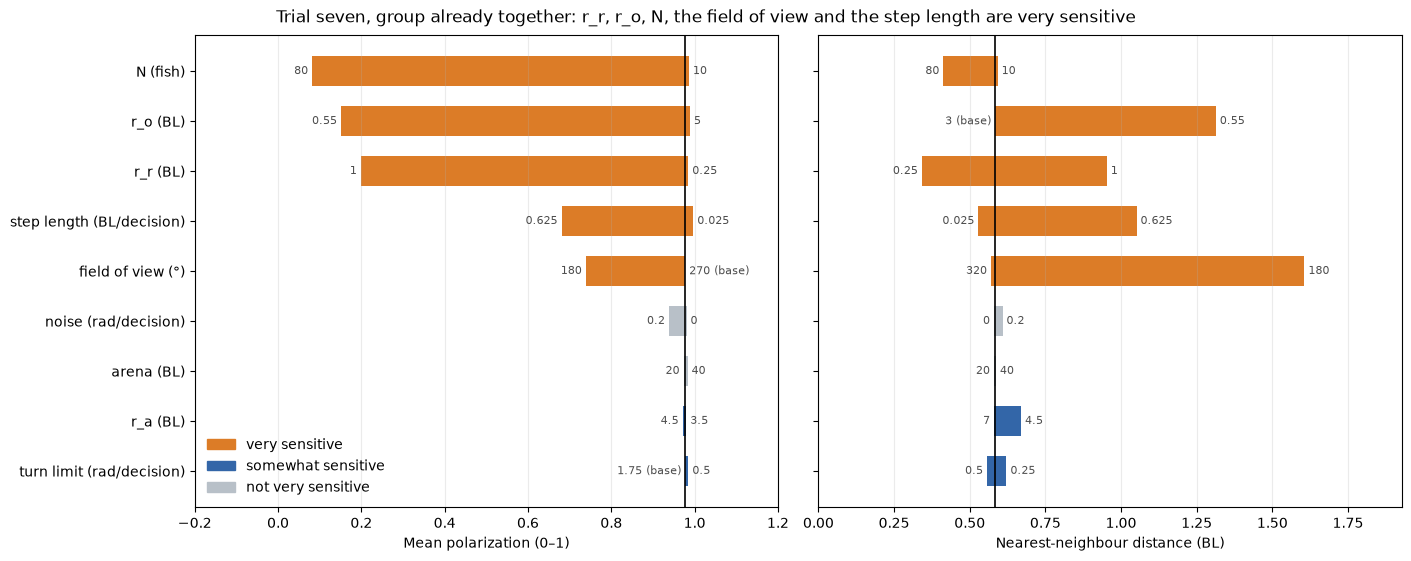

In [15]:
from matplotlib.patches import Patch

CLASS_COLORS = {"very sensitive": PUCKETT_COLOR, "somewhat sensitive": A0_COLOR, "not very sensitive": "#b8c0c8"}


def plot_tornado(summary, classes, title, file_name=None):
    """For each parameter, the range of polarization and of NND inside its range."""
    parameters = parameter_names(summary)
    base = summary[summary["parameter"] == "base"].iloc[0]

    # Order: the widest polarization range at the top.
    widths = []
    for parameter in parameters:
        rows = rows_for(summary, parameter)
        widths.append(rows["polarization"].max() - rows["polarization"].min())
    order = list(np.argsort(widths))   # smallest first, so the widest ends up at the top

    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharey=True, constrained_layout=True)
    for axis, metric, axis_label in [(axes[0], "polarization", "Mean polarization (0–1)"),
                                     (axes[1], "nnd", "Nearest-neighbour distance (BL)")]:
        for position, index in enumerate(order):
            rows = rows_for(summary, parameters[index])
            low = rows[metric].min()
            high = rows[metric].max()
            english = translate([parameters[index]], PARAMETER_NAMES)[0]
            parameter_class = classes[classes["parameter"] == english]["class"].iloc[0]
            axis.barh(position, high - low, left=low, height=0.6, color=CLASS_COLORS[parameter_class])
            axis.text(low, position, f"{rows.loc[rows[metric].idxmin(), 'value']} ", ha="right", va="center",
                      fontsize=8, color="0.3")
            axis.text(high, position, f" {rows.loc[rows[metric].idxmax(), 'value']}", ha="left", va="center",
                      fontsize=8, color="0.3")
        axis.axvline(base[metric], color="black", linewidth=1.2)
        axis.set_xlabel(axis_label)
        axis.grid(alpha=0.25, axis="x")
    axes[0].set_xlim(-0.2, 1.2)
    axes[1].set_xlim(0, summary["nnd"].max() * 1.2)
    labels = []
    for index in order:
        labels.append(translate([parameters[index]], PARAMETER_NAMES)[0])
    axes[0].set_yticks(list(range(len(order))))
    axes[0].set_yticklabels(labels)
    legend_squares = []
    for parameter_class in CLASS_COLORS:
        legend_squares.append(Patch(color=CLASS_COLORS[parameter_class], label=parameter_class))
    axes[0].legend(handles=legend_squares, frameon=False, loc="lower left")
    fig.suptitle(title)
    if file_name is not None:
        fig.savefig(FIGURE_FOLDER / file_name, dpi=150)
    plt.show()


plot_tornado(compact_summary, compact_classes, "Trial seven, group already together: r_r, r_o, N, the field of view and the step length are very sensitive", "part_b2_tornado_compact.png")

The same tornado plot with the random start (part B).

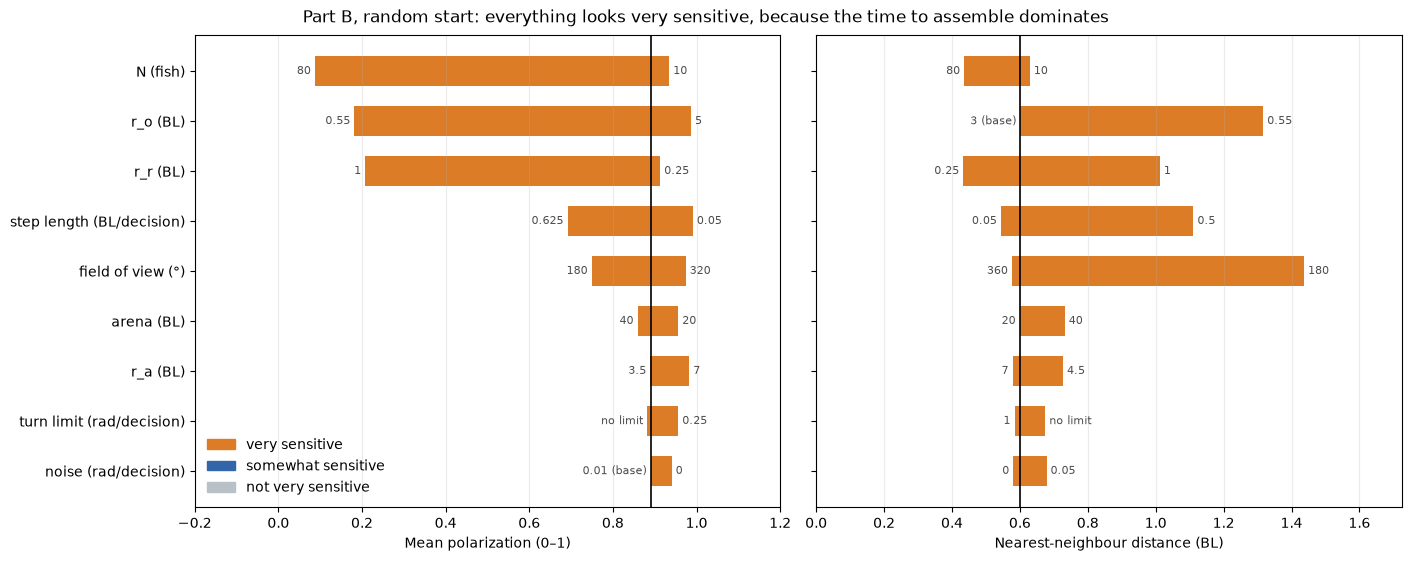

In [16]:
plot_tornado(sensitivity_summary, random_start_classes,
             "Part B, random start: everything looks very sensitive, because the time to assemble dominates")

Part A: what happens when rules are switched off (blue = A0, orange = A4).

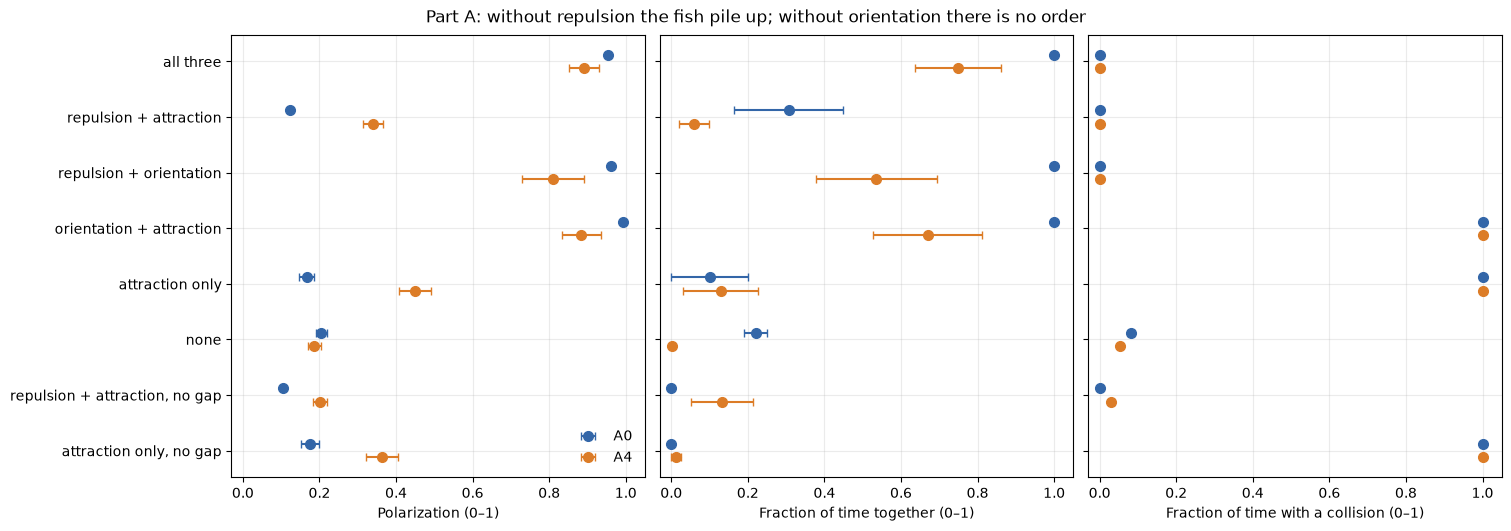

In [17]:
rule_order = []
for name, rules, english in RULE_SETS + NO_GAP_RULE_SETS:
    rule_order.append(name)
panels = [("polarization", "Polarization (0–1)"), ("together_fraction", "Fraction of time together (0–1)"),
          ("collision_fraction", "Fraction of time with a collision (0–1)")]
BASE_COLORS = {"A0": A0_COLOR, "A4": PUCKETT_COLOR}
OFFSETS = {"A0": -0.12, "A4": 0.12}

fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True, constrained_layout=True)
for axis, (column, axis_label) in zip(axes, panels):
    for base in ["A0", "A4"]:
        positions, means, errors = [], [], []
        for index in range(len(rule_order)):
            row = rules_summary[(rules_summary["base"] == base) & (rules_summary["rule_set"] == rule_order[index])]
            positions.append(index + OFFSETS[base])
            means.append(row[column].iloc[0])
            errors.append(row[column + "_se"].iloc[0])
        axis.errorbar(means, positions, xerr=errors, color=BASE_COLORS[base], marker="o",
                      markersize=7, linestyle="none", capsize=3, label=base)
    axis.set_xlim(-0.03, 1.05)
    axis.set_xlabel(axis_label)
    axis.grid(alpha=0.25)
axes[0].set_yticks(list(range(len(rule_order))))
axes[0].set_yticklabels(translate(rule_order, RULE_NAMES))
axes[0].invert_yaxis()
axes[0].legend(frameon=False, loc="lower right")
fig.suptitle("Part A: without repulsion the fish pile up; without orientation there is no order")
plt.show()

Part D: every configuration of part B2 where r_r, r_o or N changes, against its crowding number. Dashed line: N equal to the capacity.

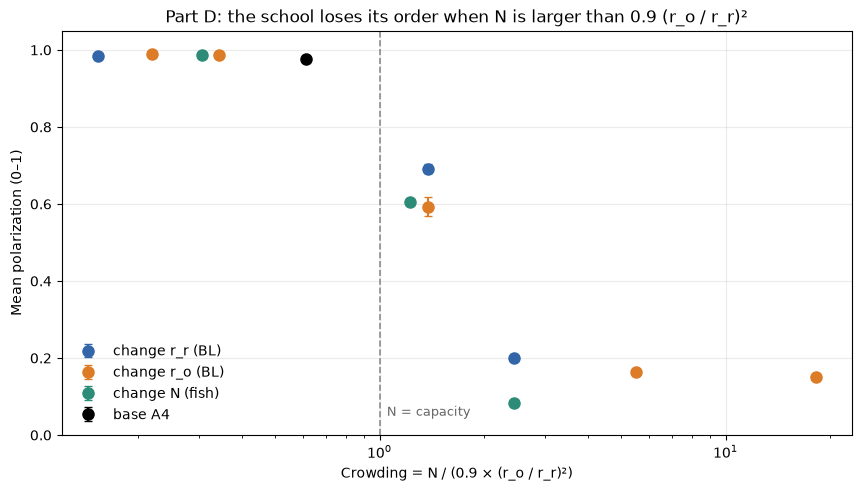

In [18]:
PARAMETER_COLORS = {"r_r (BL)": A0_COLOR, "r_o (BL)": PUCKETT_COLOR, "N (fish)": EXTRA_COLOR, "base": "black"}

fig, axis = plt.subplots(figsize=(8.5, 4.8), constrained_layout=True)
axis.axvline(1.0, color="0.55", linestyle="--", linewidth=1.2)
for parameter in PARAMETER_COLORS:
    rows = crowding[crowding["parameter"] == parameter]
    legend_text = "change " + parameter
    if parameter == "base":
        legend_text = "base A4"
    axis.errorbar(rows["crowding"], rows["polarization"], yerr=rows["polarization_se"],
                  color=PARAMETER_COLORS[parameter], marker="o", markersize=8, linestyle="none",
                  capsize=3, label=legend_text)
axis.text(1.05, 0.05, "N = capacity", color="0.4", fontsize=9)
axis.set_xscale("log")
axis.set_xlabel("Crowding = N / (0.9 × (r_o / r_r)²)")
axis.set_ylabel("Mean polarization (0–1)")
axis.set_ylim(0, 1.05)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="lower left")
axis.set_title("Part D: the school loses its order when N is larger than 0.9 (r_o / r_r)²")
plt.show()

## Conclusion

- **Essential rules:** repulsion (without it the fish pile up) and orientation (without it there is never order). Attraction is not needed to keep an assembled group together, but it helps the group to assemble.
- **With the group already together:** r_r, r_o, N, the field of view (only at 180°) and the step length (from 0.25 BL) are very sensitive; r_a and the turn limit are somewhat sensitive; noise and arena size are not very sensitive. With the random start everything looks very sensitive, because the base is on the edge of assembling.
- **Minimal model** (3 rules, 360°, instant turns, no noise, 28 BL arena, compact start): works in 10 of 10 new seeds.
- **Crowding:** r_r, r_o and N act through one number, N / (0.9 (r_o / r_r)²); the school loses its order above about 1.